# Optimized Linear Regression — From OLS to Ridge, Lasso & GridSearchCV

**Learn with Dr. Jyoti**

In this notebook we build a complete regression workflow:

**Raw Data → Train/Test Split → Baseline Linear Regression → Regression Metrics → Residual Diagnostics → Ridge/Lasso → Cross-Validation → GridSearchCV → Final Test Evaluation**



In [ ]:
# ============================================================
# 0. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load a regression dataset

We use the **California Housing** dataset. It contains continuous house-value targets and multiple numerical features.

The important idea is not the specific dataset. The same workflow can be applied to many regression problems such as:
- house-price prediction
- sales forecasting
- energy-demand prediction
- salary prediction
- crop-yield prediction

The target is a **continuous number**, so classification accuracy is not the appropriate primary metric.

In [ ]:
# Load the dataset.

housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# Quick inspection

print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())

print("\nSummary statistics:")
display(df.describe().round(2))

Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Summary statistics:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


### What should students notice?

- `MedHouseVal` is the target we want to predict.
- The remaining columns are input features.
- The target is numeric and continuous.
- Different features can have very different scales.

That last point becomes especially important when we introduce **Ridge and Lasso regularization**.

In [ ]:
# ============================================================
# 2. SEPARATE FEATURES (X) AND TARGET (y)
# ============================================================

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

X shape: (20640, 8)
y shape: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


## 3. Train/Test Split

We keep the test set completely unseen during model training and hyperparameter tuning.

This is essential because the final test set should represent **new, unseen data**.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 16512
Test samples: 4128


In [ ]:
# ============================================================
# 4. BASELINE: ORDINARY LINEAR REGRESSION
# ============================================================

baseline = LinearRegression()
baseline.fit(X_train, y_train)

print("Model trained.")
print("Intercept:", baseline.intercept_)

coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": baseline.coef_
}).sort_values("Coefficient", key=np.abs, ascending=False)

display(coef_table)

Model trained.
Intercept: -37.02327770606409


,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
7,Longitude,-0.433708
6,Latitude,-0.419792
2,AveRooms,-0.123323
1,HouseAge,0.009724
5,AveOccup,-0.003526
4,Population,-0.000002


### Interpreting coefficients

A coefficient represents the model's estimated change in the target associated with a one-unit increase in that feature, **holding the other features fixed**.

Be careful: a regression coefficient is a model relationship, not automatically a causal or biological explanation.

In [ ]:
# ============================================================
# 5. PREDICTIONS
# ============================================================

y_pred_baseline = baseline.predict(X_test)

prediction_table = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred_baseline[:10],
    "Error": y_test.values[:10] - y_pred_baseline[:10]
})

display(prediction_table.round(3))

,Actual,Predicted,Error
0,0.477,0.719,-0.242
1,0.458,1.764,-1.306
2,5.000,2.710,2.290
3,2.186,2.839,-0.653
4,2.780,2.605,0.175
5,1.587,2.012,-0.425
6,1.982,2.646,-0.664
7,1.575,2.169,-0.594
8,3.400,2.741,0.659
9,4.466,3.916,0.550


## 6. Regression metrics

For continuous targets, accuracy is usually not the right metric.

### MAE — Mean Absolute Error

Easy to interpret because it is in the same units as the target.

### MSE — Mean Squared Error

Large errors are penalized more heavily.

### RMSE — Root Mean Squared Error

Like MSE, it strongly penalizes large errors, but returns to the target's units.

### R² — Coefficient of Determination

Higher is generally better; values closer to 1 indicate that the model explains more of the target variation.

In [ ]:
# ============================================================
# 7. EVALUATE THE BASELINE MODEL
# ============================================================

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

baseline_metrics = regression_metrics(y_test, y_pred_baseline)

baseline_metrics_df = pd.DataFrame([baseline_metrics], index=["Linear Regression"])
display(baseline_metrics_df.round(4))

,MAE,MSE,RMSE,R2
Linear Regression,0.5332,0.5559,0.7456,0.5758


## 8. Diagnostic 1 — Actual vs Predicted

A strong regression model should place predictions close to the diagonal line.


The farther points move away from the diagonal, the larger the prediction errors.

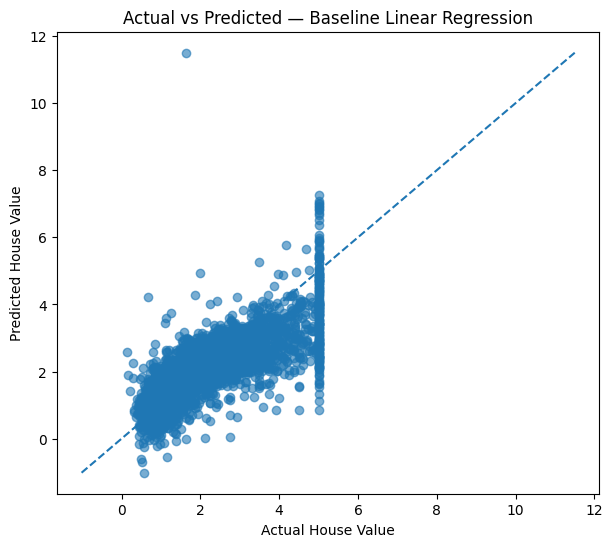

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_baseline, alpha=0.6)

line_min = min(y_test.min(), y_pred_baseline.min())
line_max = max(y_test.max(), y_pred_baseline.max())

plt.plot([line_min, line_max], [line_min, line_max], linestyle="--")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted — Baseline Linear Regression")
plt.show()

## 9. Diagnostic 2 — Residual Plot

Residuals are:


e_i = y_i - \hat{y}_i


A healthy residual plot should look roughly like random scatter around zero.

Watch for:
- a **curve** → possible non-linearity
- a **funnel shape** → changing error variance
- strong clusters → missing structure or important variables
- extreme points → possible outliers

This is why we should not simply **worship one metric such as R²**.

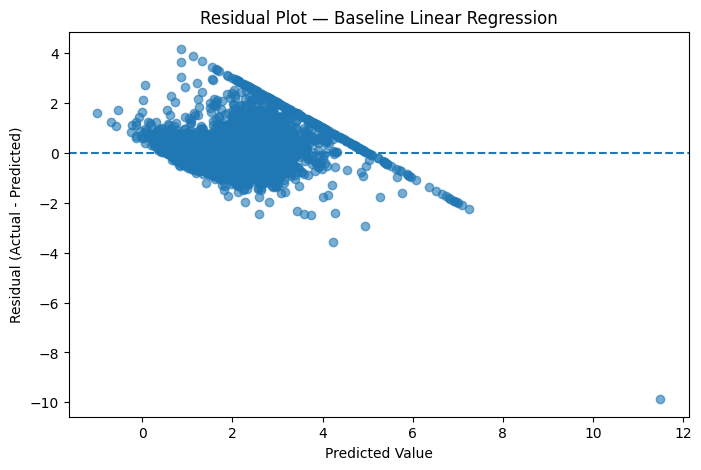

In [ ]:
residuals = y_test - y_pred_baseline

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_baseline, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Value")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot — Baseline Linear Regression")
plt.show()

# 10. Why Regularization?

Imagine giving a model many useful, redundant and noisy features.

A flexible model can start fitting noise instead of learning a stable relationship.

Regularization adds a penalty for large coefficients.

### Ridge — L2 penalty

Ridge tends to **shrink coefficients toward zero**, but usually does not make them exactly zero.

### Lasso — L1 penalty

Lasso can push some coefficients **exactly to zero**, which makes it useful for feature selection.

### Important

Because the penalty acts on coefficient magnitudes, **feature scaling is important before Ridge/Lasso**.

In [ ]:
# ============================================================
# 11. RIDGE AND LASSO WITH PROPER SCALING
# ============================================================

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.01, max_iter=10000))
])

ridge_pipeline.fit(X_train, y_train)
lasso_pipeline.fit(X_train, y_train)

y_pred_ridge = ridge_pipeline.predict(X_test)
y_pred_lasso = lasso_pipeline.predict(X_test)

results = pd.DataFrame([
    regression_metrics(y_test, y_pred_baseline),
    regression_metrics(y_test, y_pred_ridge),
    regression_metrics(y_test, y_pred_lasso)
], index=["Linear Regression", "Ridge", "Lasso"])

display(results.round(4))

,MAE,MSE,RMSE,R2
Linear Regression,0.5332,0.5559,0.7456,0.5758
Ridge,0.5332,0.5559,0.7456,0.5758
Lasso,0.5353,0.5483,0.7404,0.5816


## 12. Compare coefficient sizes

Because Ridge and Lasso use standardized inputs, their coefficients are on a comparable standardized-feature scale.

**Regularization is not just about improving one score. It also controls model complexity.**

In [ ]:
# Extract standardized coefficients from Ridge and Lasso

ridge_coef = ridge_pipeline.named_steps["model"].coef_
lasso_coef = lasso_pipeline.named_steps["model"].coef_

coef_compare = pd.DataFrame({
    "Feature": X.columns,
    "Ridge": ridge_coef,
    "Lasso": lasso_coef
})

display(coef_compare.sort_values("Ridge", key=np.abs, ascending=False).round(4))

,Feature,Ridge,Lasso
6,Latitude,-0.8962,-0.7901
7,Longitude,-0.8691,-0.7557
0,MedInc,0.8543,0.8010
3,AveBedrms,0.3390,0.2062
2,AveRooms,-0.2942,-0.1628
1,HouseAge,0.1226,0.1271
5,AveOccup,-0.0408,-0.0306
4,Population,-0.0023,-0.0000


## 13. See Lasso's feature-selection effect

Lasso can set coefficients to exactly zero.

Count how many coefficients are zero?

> “If a coefficient becomes zero, what does that mean for the Lasso model?”

In [ ]:
zero_lasso = np.isclose(lasso_coef, 0)

print("Number of Lasso coefficients:", len(lasso_coef))
print("Number exactly/approximately zero:", zero_lasso.sum())

lasso_features = pd.DataFrame({
    "Feature": X.columns,
    "Lasso Coefficient": lasso_coef,
    "Selected?": np.where(zero_lasso, "No", "Yes")
})

display(lasso_features.round(4))

Number of Lasso coefficients: 8
Number exactly/approximately zero: 1


,Feature,Lasso Coefficient,Selected?
0,MedInc,0.8010,Yes
1,HouseAge,0.1271,Yes
2,AveRooms,-0.1628,Yes
3,AveBedrms,0.2062,Yes
4,Population,-0.0000,No
5,AveOccup,-0.0306,Yes
6,Latitude,-0.7901,Yes
7,Longitude,-0.7557,Yes


# 14. Hyperparameter tuning with GridSearchCV

The regularization strength **alpha** is a hyperparameter.

Instead of guessing one value, we can test several values using cross-validation.

We will:
1. scale the features inside a Pipeline
2. try multiple Ridge `alpha` values
3. use **5-fold cross-validation**
4. select the configuration with the best cross-validation score
5. evaluate the final selected model once on the untouched test set

### Important data-leakage rule

The test set is **not** used to choose alpha.

In [ ]:
# ============================================================
# 15. RIDGE GRID SEARCH
# ============================================================

ridge_for_search = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=ridge_for_search,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV RMSE:", -grid.best_score_)

Best parameters: {'model__alpha': 0.001}
Best CV RMSE: 0.7205271876569361


### Why `neg_root_mean_squared_error`?

`GridSearchCV` tries to **maximize** a scoring value.

Because RMSE is normally minimized, scikit-learn exposes it as a negative score:

- better RMSE → less negative score
- `grid.best_score_` is therefore negative
- multiplying by `-1` gives the familiar positive RMSE

In [ ]:
# ============================================================
# 16. FINAL TUNED RIDGE MODEL
# ============================================================

best_ridge = grid.best_estimator_

y_pred_best_ridge = best_ridge.predict(X_test)

tuned_metrics = regression_metrics(y_test, y_pred_best_ridge)

comparison = pd.DataFrame([
    regression_metrics(y_test, y_pred_baseline),
    regression_metrics(y_test, y_pred_ridge),
    regression_metrics(y_test, y_pred_lasso),
    tuned_metrics
], index=[
    "Linear Regression",
    "Ridge (alpha=1)",
    "Lasso (alpha=0.01)",
    "Tuned Ridge"
])

display(comparison.round(4))

,MAE,MSE,RMSE,R2
Linear Regression,0.5332,0.5559,0.7456,0.5758
Ridge (alpha=1),0.5332,0.5559,0.7456,0.5758
Lasso (alpha=0.01),0.5353,0.5483,0.7404,0.5816
Tuned Ridge,0.5332,0.5559,0.7456,0.5758


## 17. Final model comparison

Interpret the table carefully:

- **Lower MAE** → smaller average absolute error
- **Lower RMSE** → fewer/lower large errors
- **Higher R²** → more variance explained

Do not automatically declare a winner from one metric. The appropriate model depends on the problem, error costs, interpretability requirements and generalization performance.

In [ ]:
# Sort by RMSE so the lowest error appears first.

final_comparison = comparison.sort_values("RMSE")
display(final_comparison.round(4))

,MAE,MSE,RMSE,R2
Lasso (alpha=0.01),0.5353,0.5483,0.7404,0.5816
Ridge (alpha=1),0.5332,0.5559,0.7456,0.5758
Tuned Ridge,0.5332,0.5559,0.7456,0.5758
Linear Regression,0.5332,0.5559,0.7456,0.5758


## 18. Final diagnostic plot for the tuned model

We now inspect the tuned model rather than stopping at the score table.

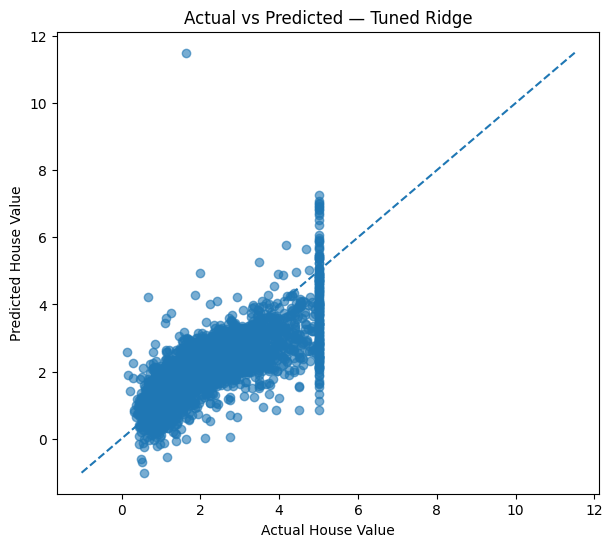

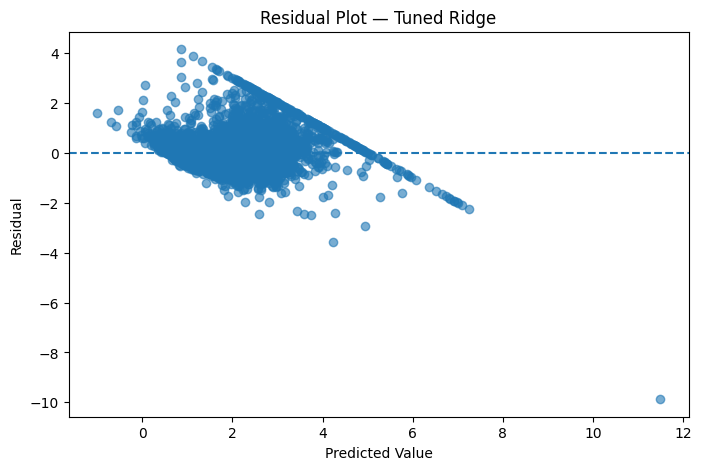

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_best_ridge, alpha=0.6)

line_min = min(y_test.min(), y_pred_best_ridge.min())
line_max = max(y_test.max(), y_pred_best_ridge.max())

plt.plot([line_min, line_max], [line_min, line_max], linestyle="--")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted — Tuned Ridge")
plt.show()

final_residuals = y_test - y_pred_best_ridge

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_best_ridge, final_residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Value")
plt.ylabel("Residual")
plt.title("Residual Plot — Tuned Ridge")
plt.show()

# 20. The complete regression workflow

### Remember this pipeline

**Raw Data**  
↓  
**Select Features and Target**  
↓  
**Train/Test Split**  
↓  
**Baseline Linear Regression**  
↓  
**MAE + MSE + RMSE + R²**  
↓  
**Actual-vs-Predicted + Residual Diagnostics**  
↓  
**Scale Features**  
↓  
**Ridge / Lasso**  
↓  
**Cross-Validation + GridSearchCV**  
↓  
**Final Evaluation on Untouched Test Set**

### Four critical pitfalls

1. **Tuning on test data** → data leakage  
2. **Comparing models on different test subsets** → unfair comparison  
3. **Looking only at R²** → incomplete diagnosis  
4. **Skipping scaling for Ridge/Lasso** → unfair regularization

---

## Challenge

Try these changes yourself:

**Challenge 1:** Change the Ridge alpha grid.  
**Challenge 2:** Add more alpha values on a logarithmic scale.  
**Challenge 3:** Compare the number of zero coefficients for different Lasso alpha values.  
**Challenge 4:** Change the train/test split from 80/20 to 70/30.  
**Challenge 5:** Which model has the lowest RMSE? Is it also the model you would deploy? Explain why.

### Next concept

What if the true relationship is **not a straight line**?

That leads naturally to **Polynomial Regression and nonlinear models**.